# 05 — Statistics, Probability and Hypothesis Testing

## Purpose
Notebook 04 described patterns. This notebook asks which of them are **statistically reliable**, **how large** they are, and **how uncertain** the estimates are. It covers descriptive statistics, probability distributions, sampling, confidence intervals and hypothesis tests, followed by an adjusted model.

## Ground rules
- **Data:** the Gold tables, with the populations and business rules of notebook 04:
  - item-based order value (Q-03);
  - the D-06 delivery population;
  - one unshared review per order (Q-04 / D-07);
  - the candidate window for time series (Q-11).
- **Observational data:** nothing here was randomised, so results are **associations, not causal effects**.
- **Large samples:** with n around 95,000, almost any difference is "significant". Every test therefore reports an **effect size with a confidence interval**, and conclusions rest on effect size, not on the p-value alone.
- **Multiple testing:** the seven formal tests form one family, and their p-values are Holm-adjusted in section 6.
- **Reproducibility:** all random procedures (sampling, bootstrap) use the fixed seed 42.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import roc_auc_score
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (confint_proportions_2indep, proportion_confint, proportion_effectsize,
                                          proportions_ztest)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = np.random.default_rng(42)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
GOLD = ROOT / "data" / "processed" / "analytical"
orders = pd.read_parquet(GOLD / "fact_orders.parquet")
reviews = pd.read_parquet(GOLD / "fact_reviews.parquet")
assert (len(orders), len(reviews)) == (99_441, 99_224)

REGION = {**dict.fromkeys(["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "Norte"),
          **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Nordeste"),
          **dict.fromkeys(["DF", "GO", "MT", "MS"], "Centro-Oeste"),
          **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Sudeste"), **dict.fromkeys(["PR", "RS", "SC"], "Sul")}
REGION_ORDER = ["Sudeste", "Sul", "Centro-Oeste", "Nordeste", "Norte"]
orders["region"] = orders["customer_state_std"].map(REGION)

ov = orders.loc[orders["has_items"], "items_price_total"].to_numpy()
eligible = orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].notna()].copy()   # D-06
one = eligible[eligible["review_count"] == 1]
rv = reviews[reviews["order_id"].isin(one["order_id"]) & ~reviews["dq_review_id_shared"]]
reviewed = one.merge(rv[["order_id", "review_score"]], on="order_id", validate="1:1")
reviewed["low_review"] = (reviewed["review_score"] <= 2).astype(int)        # analysis definition: 1-2 stars
late, ontime = reviewed[reviewed["is_late"]], reviewed[~reviewed["is_late"]]

def fmt_p(p):
    return "< 1e-300" if p == 0 else (f"{p:.2e}" if p < 1e-4 else f"{p:.4f}")

TESTS = []   # family of formal tests, Holm-adjusted in section 6
print(f"order values {len(ov):,} | eligible {len(eligible):,} | reviewed {len(reviewed):,} (late {len(late):,}, on time {len(ontime):,})")

order values 98,666 | eligible 96,470 | reviewed 94,430 (late 6,287, on time 88,143)


## 1. Descriptive statistics: location, spread and shape
**Question:** which summary statistics describe order value faithfully?

In [2]:
def describe(x):
    x = np.asarray(x)
    q1, q3 = np.percentile(x, [25, 75])
    return {"n": len(x), "mean": x.mean(), "median": np.median(x), "trimmed mean 10%": stats.trim_mean(x, .1),
            "geometric mean": stats.gmean(x), "variance": x.var(ddof=1), "std": x.std(ddof=1),
            "coef. variation": x.std(ddof=1) / x.mean(), "IQR": q3 - q1, "MAD (scaled)": stats.median_abs_deviation(x, scale="normal"),
            "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x)}

has = orders[orders["has_items"]]
table = pd.DataFrame({"all": describe(ov), **{r: describe(has.loc[has["region"] == r, "items_price_total"]) for r in REGION_ORDER}})
display(table)

,all,Sudeste,Sul,Centro-Oeste,Nordeste,Norte
n,"98,666.0000","67,706.0000","14,042.0000","5,744.0000","9,336.0000","1,838.0000"
mean,137.7541,131.2645,139.1498,151.5428,165.5413,181.9117
median,86.9000,82.9900,89.0000,89.9900,99.0000,105.0000
trimmed mean 10%,99.1314,95.6887,100.3861,105.6693,116.3902,125.7657
geometric mean,85.0844,82.2816,86.0754,90.4778,98.6985,103.8657
variance,"44,371.3772","40,542.0550","41,006.7112","63,001.3910","59,172.9214","69,824.3067"
std,210.6451,201.3506,202.5011,251.0008,243.2548,264.2429
coef. variation,1.5291,1.5339,1.4553,1.6563,1.4695,1.4526
IQR,104.0000,103.0100,102.0900,110.9000,128.0100,145.0900
MAD (scaled),71.0166,68.2145,72.6623,74.2635,80.2088,95.3313


**Interpretation.**
- **Location:** the measures diverge sharply. Mean 137.75, 10% trimmed mean 99.13, median 86.90, geometric mean 85.08 BRL. The mean is pulled up by the heavy upper tail (skewness 9.7, excess kurtosis 266), so it describes **revenue per order**. The median or geometric mean describes the **typical customer**.
- **Spread:** the variance (44,371 BRL²) and standard deviation (211 BRL) are dominated by a few very large orders. The robust spread measures, IQR 104 BRL and scaled MAD 71 BRL, describe the bulk of orders far better.
- **Regions:** every location measure rises from Sudeste to Norte (median 83 → 105 BRL), and the ranking is the same whichever measure is used. Section 3.2 shows these regional differences still explain very little of the total variation.

## 2. Probability distributions
### 2.1 Order value: normal or log-normal?
- **Method:** fit both distributions by maximum likelihood, then compare them with AIC, Q–Q plots and quantiles.
- **Why not KS alone:** with n = 98,666, a Kolmogorov–Smirnov test rejects any parametric model, so its D statistic is reported only as a distance.

,normal,log-normal,empirical
log-likelihood,"-667,880.8501","-571,626.6563",NaN
AIC,"1,335,765.7003","1,143,257.3126",NaN
KS D,0.2675,0.0288,NaN
P(value < 0),0.2566,0.0000,NaN
p50,137.7541,85.0844,86.9000
p90,407.7053,281.3823,269.9000
p99,627.7855,746.0715,998.9000


log-normal parameters: mu(log) = 4.444, sigma(log) = 0.933


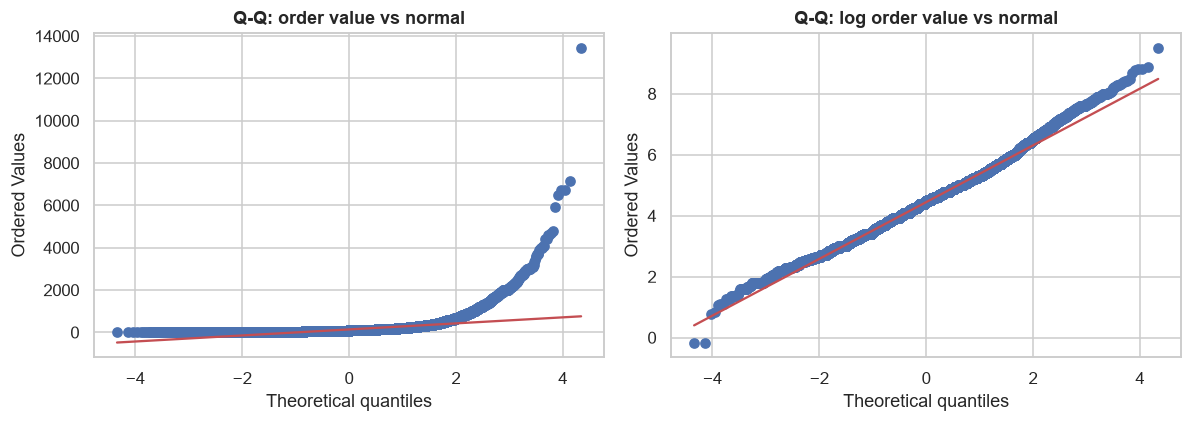

In [3]:
mu, sd = stats.norm.fit(ov)
shape, loc, scale = stats.lognorm.fit(ov, floc=0)
ll_norm = stats.norm.logpdf(ov, mu, sd).sum()
ll_logn = stats.lognorm.logpdf(ov, shape, loc, scale).sum()
fits = pd.DataFrame({
    "normal": {"log-likelihood": ll_norm, "AIC": 4 - 2 * ll_norm, "KS D": stats.kstest(ov, stats.norm(mu, sd).cdf).statistic,
               "P(value < 0)": stats.norm.cdf(0, mu, sd), "p50": stats.norm.ppf(.5, mu, sd), "p90": stats.norm.ppf(.9, mu, sd),
               "p99": stats.norm.ppf(.99, mu, sd)},
    "log-normal": {"log-likelihood": ll_logn, "AIC": 4 - 2 * ll_logn, "KS D": stats.kstest(ov, stats.lognorm(shape, loc, scale).cdf).statistic,
                   "P(value < 0)": 0.0, "p50": stats.lognorm.ppf(.5, shape, loc, scale), "p90": stats.lognorm.ppf(.9, shape, loc, scale),
                   "p99": stats.lognorm.ppf(.99, shape, loc, scale)},
    "empirical": {"p50": np.median(ov), "p90": np.percentile(ov, 90), "p99": np.percentile(ov, 99)}})
display(fits)
print(f"log-normal parameters: mu(log) = {np.log(scale):.3f}, sigma(log) = {shape:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
stats.probplot(ov, dist="norm", plot=ax[0]); ax[0].set_title("Q-Q: order value vs normal")
stats.probplot(np.log(ov), dist="norm", plot=ax[1]); ax[1].set_title("Q-Q: log order value vs normal")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Log-normal fits far better than normal:**
  - AIC 1,143,257 vs 1,335,766, a log-likelihood gain of about 96,000;
  - KS distance 0.029 vs 0.268;
  - the log Q–Q plot is close to a straight line;
  - the normal fit is plainly unusable: it gives a **26% probability to negative order values**.
- **The log-normal model** (μ_log = 4.44, σ_log = 0.93) reproduces the median (85 vs 87 BRL) and p90 (281 vs 270) well.
- **But it underestimates the extreme tail:** p99 is 746 against 999 observed. Real large orders are more frequent than the model predicts, which matches the upward bend at the right of the Q–Q plot.
- **Practical rule:** log-scale methods work for typical behaviour, but risk or revenue planning for very large orders shouldn't rely on a log-normal tail.

### 2.2 Daily order counts: Poisson or negative binomial?
- **Question:** are daily orders as regular as a Poisson process, after accounting for weekday and month?
- **Method:** a Poisson GLM with weekday and month effects. A Pearson dispersion (χ²/df) far above 1 means overdispersion, and a negative-binomial (NB2) model is then compared with a likelihood-ratio test.

In [4]:
win = orders[orders["in_candidate_window"]]
daily = (win.groupby("purchase_date").size().reindex(pd.date_range("2017-01-01", "2018-08-31"), fill_value=0)
         .rename("orders").to_frame())
daily["weekday"], daily["month"] = daily.index.day_name(), daily.index.strftime("%Y-%m")
pois = smf.glm("orders ~ C(weekday) + C(month)", data=daily, family=sm.families.Poisson()).fit()
nb = smf.negativebinomial("orders ~ C(weekday) + C(month)", data=daily).fit(disp=False)
dispersion = pois.pearson_chi2 / pois.df_resid
lr = 2 * (nb.llf - pois.llf)
p_lr = 0.5 * stats.chi2.sf(lr, 1)            # alpha = 0 is on the boundary: halved chi2(1)
print(f"days {len(daily)} | Poisson Pearson dispersion = {dispersion:.1f} (1 = Poisson)")
print(f"NB2 alpha = {nb.params['alpha']:.4f} | AIC Poisson {pois.aic:,.0f} vs NB {nb.aic:,.0f} | LR = {lr:,.0f}, p = {fmt_p(p_lr)}")
print(f"implied variance at the mean daily volume ({daily['orders'].mean():.0f}): Poisson {daily['orders'].mean():.0f}, "
      f"NB {daily['orders'].mean() + nb.params['alpha'] * daily['orders'].mean() ** 2:.0f}")

days 608 | Poisson Pearson dispersion = 17.4 (1 = Poisson)
NB2 alpha = 0.0984 | AIC Poisson 13,388 vs NB 6,484 | LR = 6,906, p = < 1e-300
implied variance at the mean daily volume (163): Poisson 163, NB 2777


**Interpretation.**
- **Overdispersion:** even after weekday and month effects, daily counts are **17× more variable than a Poisson process** (Pearson dispersion 17.4).
- **Negative binomial fits far better:** AIC 6,484 vs 13,388, and the likelihood-ratio test gives p < 1e-300. Its α of 0.098 implies a daily variance of about 2,800 at the mean volume, against 163 under Poisson.
- **Business meaning:** demand has substantial day-to-day variability beyond calendar effects. Promotions, Black Friday and seller campaigns cluster orders. Capacity planning or forecast intervals built on Poisson assumptions would be **far too narrow**.

## 3. Sampling
### 3.1 Sampling distribution of the mean (central limit theorem)
- **Question:** how large must a random sample of orders be for the sample mean to be approximately normal, given this skewed population?
- **Method:** draw 5,000 simple random samples for each size n and compare their spread with σ/√n.

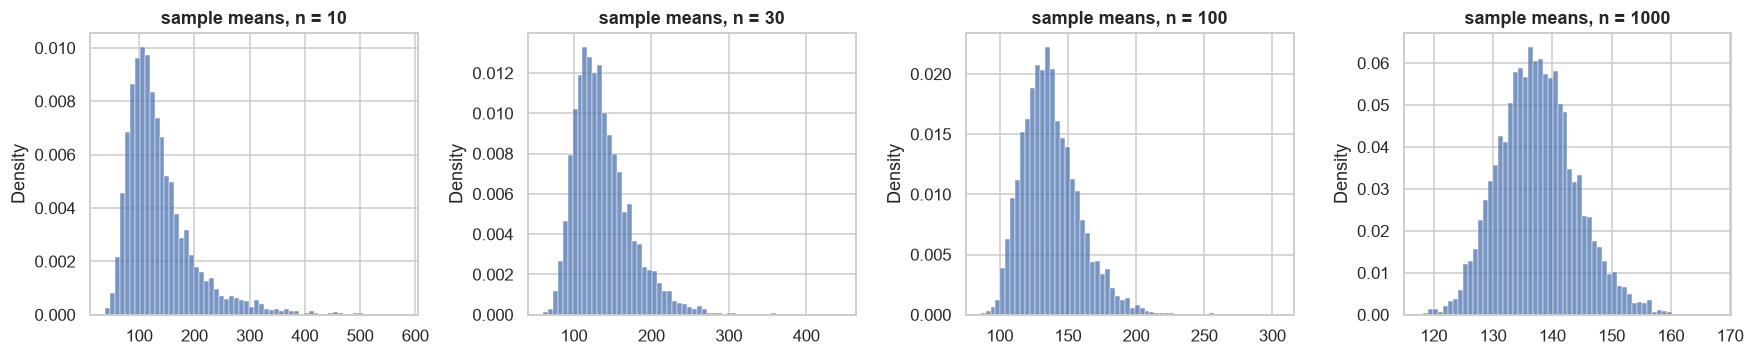

,empirical SE,sigma/sqrt(n),skewness of means,95% interval coverage of mu
n,,,,
10,63.0490,66.6115,1.9446,0.9484
30,37.9022,38.4582,1.4413,0.9562
100,21.3446,21.0644,1.0645,0.9578
1000,6.5881,6.6612,0.3237,0.9506


In [5]:
sigma = ov.std(ddof=0)
rows, fig, axes = [], plt.subplots(1, 4, figsize=(16, 3.4))[0], None
axes = fig.axes
for ax, n in zip(axes, (10, 30, 100, 1000)):
    means = rng.choice(ov, size=(5000, n), replace=True).mean(axis=1)
    rows.append({"n": n, "empirical SE": means.std(ddof=1), "sigma/sqrt(n)": sigma / np.sqrt(n), "skewness of means": stats.skew(means),
                 "95% interval coverage of mu": np.mean(np.abs(means - ov.mean()) <= 1.96 * means.std(ddof=1))})
    sns.histplot(means, bins=60, ax=ax, stat="density"); ax.set_title(f"sample means, n = {n}")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("n"))

**Interpretation.** The empirical standard error matches σ/√n closely at every size, which confirms the theory. Two things improve differently as n grows:
- **Coverage is reliable even at small n:** the nominal ±1.96·SE interval already covers the true mean about 95% of the time (95–96%) at n = 10.
- **The sampling distribution's shape converges slowly** because the population is so skewed. The means are still clearly skewed at n = 30 (skewness 1.44) and n = 100 (1.06), and only approach symmetry at n = 1,000 (0.32).

**Practical rule:** the textbook "n ≥ 30 is enough" doesn't hold for revenue-like data. Use samples of several hundred or more, a log transform, or a bootstrap.

### 3.2 Simple random vs stratified sampling
- **Question:** does stratifying by region give a more precise estimate of mean order value for the same sample size?
- **Method:** 2,000 repetitions of n = 1,000, with proportional allocation across the five regions.

In [6]:
pop = has[["region", "items_price_total"]].reset_index(drop=True)
groups = {r: g["items_price_total"].to_numpy() for r, g in pop.groupby("region")}
weights = {r: len(v) / len(pop) for r, v in groups.items()}
alloc = {r: max(2, round(1000 * w)) for r, w in weights.items()}
srs = np.array([rng.choice(pop["items_price_total"].to_numpy(), 1000, replace=False).mean() for _ in range(2000)])
strat = np.array([sum(weights[r] * rng.choice(groups[r], alloc[r], replace=False).mean() for r in groups) for _ in range(2000)])
print("allocation:", alloc)
print(f"true mean {pop['items_price_total'].mean():.2f} | SRS mean {srs.mean():.2f}, SE {srs.std(ddof=1):.2f} | "
      f"stratified mean {strat.mean():.2f}, SE {strat.std(ddof=1):.2f} | design effect {strat.var(ddof=1) / srs.var(ddof=1):.3f}")
print("share of total variance between regions:", round(sum(weights[r] * (groups[r].mean() - pop['items_price_total'].mean()) ** 2
      for r in groups) / pop['items_price_total'].var(ddof=0), 4))

allocation: {'Centro-Oeste': 58, 'Nordeste': 95, 'Norte': 19, 'Sudeste': 686, 'Sul': 142}
true mean 137.75 | SRS mean 137.91, SE 6.74 | stratified mean 137.93, SE 6.67 | design effect 0.979
share of total variance between regions: 0.0034


**Interpretation.**
- **Stratifying by region barely helps here.** The design effect is 0.979, only about a 2% variance reduction (SE 6.67 vs 6.74 BRL).
- **The reason:** regions explain only 0.34% of the variance in order value. Stratification pays off only when the strata differ strongly in the outcome.
- **Where it would matter:**
  - when estimating **region-specific** quantities, because proportional allocation guarantees every region is represented (Norte gets 19 of 1,000);
  - for a variable that differs strongly between regions, such as delivery time.

## 4. Confidence intervals

,estimate,low,high
mean order value (t),137.7541,136.4397,139.0685
mean order value (bootstrap),137.7541,136.4221,139.0697
median order value (bootstrap),86.9000,85.5000,87.9900
late-delivery rate (Wilson),0.0677,0.0662,0.0693
repeat-customer rate (Wilson),0.0312,0.0301,0.0323


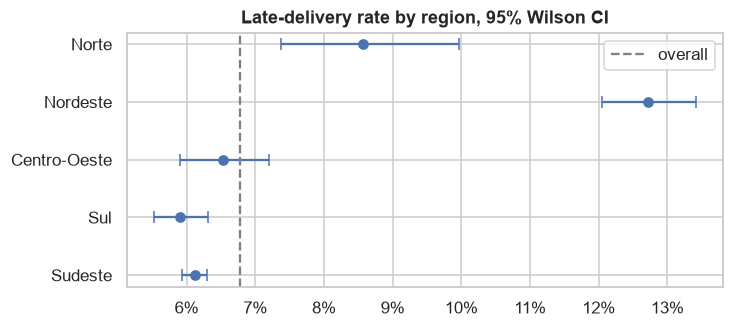

,sum,size,rate,low,high
region,,,,,
Sudeste,4048,66193,0.0612,0.0594,0.0630
Sul,815,13813,0.0590,0.0552,0.0631
Centro-Oeste,367,5624,0.0653,0.0591,0.0720
Nordeste,1150,9044,0.1272,0.1204,0.1342
Norte,154,1796,0.0857,0.0737,0.0996


In [7]:
n = len(ov); se = ov.std(ddof=1) / np.sqrt(n)
t_ci = stats.t.interval(.95, n - 1, loc=ov.mean(), scale=se)
boot_mean = stats.bootstrap((ov,), np.mean, n_resamples=2000, method="percentile", random_state=42, batch=100).confidence_interval
boot_median = stats.bootstrap((ov,), np.median, n_resamples=2000, method="percentile", random_state=42, batch=100).confidence_interval

late_n, elig_n = int(eligible["is_late"].sum()), len(eligible)
persons = orders.groupby("customer_unique_id").size()
rep_n = int((persons > 1).sum())
ci = pd.DataFrame({
    "estimate": [ov.mean(), ov.mean(), np.median(ov), late_n / elig_n, rep_n / len(persons)],
    "low": [t_ci[0], boot_mean.low, boot_median.low, *proportion_confint(late_n, elig_n, method="wilson")[:1],
            proportion_confint(rep_n, len(persons), method="wilson")[0]],
    "high": [t_ci[1], boot_mean.high, boot_median.high, proportion_confint(late_n, elig_n, method="wilson")[1],
             proportion_confint(rep_n, len(persons), method="wilson")[1]]},
    index=["mean order value (t)", "mean order value (bootstrap)", "median order value (bootstrap)",
           "late-delivery rate (Wilson)", "repeat-customer rate (Wilson)"])
display(ci)

reg = eligible.groupby("region")["is_late"].agg(["sum", "size"]).reindex(REGION_ORDER)
reg["rate"] = reg["sum"] / reg["size"]
reg[["low", "high"]] = np.column_stack(proportion_confint(reg["sum"], reg["size"], method="wilson"))
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(reg["rate"], range(len(reg)), xerr=[reg["rate"] - reg["low"], reg["high"] - reg["rate"]], fmt="o", capsize=4)
ax.axvline(late_n / elig_n, color="gray", ls="--", label="overall"); ax.set_yticks(range(len(reg)), reg.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_title("Late-delivery rate by region, 95% Wilson CI"); ax.legend()
plt.show()
display(reg)

**Interpretation (95% intervals).**
- **Mean order value:** 137.75 BRL (136.44 to 139.07). The t interval and the bootstrap agree to within 0.02 BRL: with n ≈ 99,000 the CLT holds despite the skew.
- **Median order value:** 86.90 BRL (85.50 to 87.99).
- **Late-delivery rate:** 6.77% (6.62% to 6.93%).
- **Repeat-customer rate:** 3.12% (3.01% to 3.23%).

The overall estimates are very precise. **By region**, Nordeste's late rate (12.7%, 12.0% to 13.4%) doesn't overlap any other region's interval and is about twice Sudeste's. Norte (8.6%) is also above the national rate, though its interval is wider (7.4% to 10.0%) because it has fewer orders. Sudeste, Sul and Centro-Oeste overlap, at about 6%.

## 5. Hypothesis tests
Each test states its question, hypotheses, test choice and assumption checks. The tests are two-sided, with α = 0.05 before multiple-testing correction.

### T1. Do late deliveries receive lower review scores?
- **H0:** review scores of late and on-time orders come from the same distribution. **H1:** they don't.
- **Test:** Mann–Whitney U. Scores are ordinal (1–5) and far from normal, so a t-test on means isn't appropriate.
- **Assumptions:**
  - independent observations: one unshared review per order, and 97% of people have a single order;
  - ordinal data.
- **Interpretation of the test:** the two distributions differ in shape as well as location, so MWU is read as stochastic superiority, not as a difference in medians.
- **Effect size:** the probability of superiority and the rank-biserial correlation, plus the mean difference with a Welch confidence interval.

In [8]:
u = stats.mannwhitneyu(late["review_score"], ontime["review_score"], alternative="two-sided")
n1, n2 = len(late), len(ontime)
ps = u.statistic / (n1 * n2)                     # P(late > on time) + 0.5 P(tie)
diff = late["review_score"].mean() - ontime["review_score"].mean()
se_d = np.sqrt(late["review_score"].var(ddof=1) / n1 + ontime["review_score"].var(ddof=1) / n2)
print(f"U = {u.statistic:,.0f}, p = {fmt_p(u.pvalue)} | P(late score > on-time score) = {ps:.3f}, rank-biserial r = {2 * ps - 1:.3f}")
print(f"mean score late {late['review_score'].mean():.3f} vs on time {ontime['review_score'].mean():.3f}: "
      f"difference {diff:.3f} (95% CI {diff - 1.96 * se_d:.3f} to {diff + 1.96 * se_d:.3f})")
TESTS.append(("T1 review score: late vs on time (Mann-Whitney)", u.pvalue, f"rank-biserial r = {2 * ps - 1:.2f}"))

U = 100,030,697, p = < 1e-300 | P(late score > on-time score) = 0.181, rank-biserial r = -0.639
mean score late 2.272 vs on time 4.295: difference -2.022 (95% CI -2.062 to -1.983)


**Result.** Reject H0 (p < 1e-300). The effect is **large**:
- A randomly chosen late order has only an **18% chance** of a higher score than a random on-time order (rank-biserial r = −0.64).
- The mean score is **2.0 points lower** (2.27 vs 4.30; 95% CI −2.06 to −1.98) on a 1–5 scale.

**Business meaning:** lateness is associated with roughly halving the review score. This is the largest relationship in the dataset, and it is both statistically and practically significant.

### T2. Is the share of 1–2 star reviews higher for late deliveries?
- **H0:** p_late = p_on-time. **H1:** they differ.
- **Test:** a two-proportion z-test, with Newcomb CIs for the risk difference and log CIs for the risk ratio.
- **Assumptions:** independent observations, and at least 10 successes and failures in each group (checked below).

In [9]:
k1, k2 = int(late["low_review"].sum()), int(ontime["low_review"].sum())
assert min(k1, n1 - k1, k2, n2 - k2) >= 10
z, p = proportions_ztest([k1, k2], [n1, n2])
rd = confint_proportions_2indep(k1, n1, k2, n2, method="newcomb", compare="diff")
rr = confint_proportions_2indep(k1, n1, k2, n2, method="log", compare="ratio")
print(f"1-2 star share: late {k1 / n1:.1%} ({k1:,}/{n1:,}) vs on time {k2 / n2:.1%} ({k2:,}/{n2:,}) | z = {z:.1f}, p = {fmt_p(p)}")
print(f"risk difference {k1 / n1 - k2 / n2:+.1%} (95% CI {rd[0]:+.1%} to {rd[1]:+.1%}) | "
      f"risk ratio {(k1 / n1) / (k2 / n2):.2f} (95% CI {rr[0]:.2f} to {rr[1]:.2f})")
TESTS.append(("T2 1-2 star share: late vs on time (two-proportion z)", p, f"risk ratio {(k1 / n1) / (k2 / n2):.2f}"))

1-2 star share: late 62.3% (3,918/6,287) vs on time 9.2% (8,070/88,143) | z = 122.3, p = < 1e-300
risk difference +53.2% (95% CI +51.9% to +54.4%) | risk ratio 6.81 (95% CI 6.62 to 7.00)


**Result.** Reject H0 (z = 122, p < 1e-300). The share of 1–2 star reviews is **62.3% for late orders against 9.2% for on-time ones**: a risk difference of +53 points (95% CI +51.9 to +54.4) and a **risk ratio of 6.8** (6.6 to 7.0).

**Business meaning:**
- Late orders are 7% of reviewed orders (6,287 of 94,430) but produce about **one-third of all 1–2 star reviews** (3,918 of 11,988).
- Preventing lateness is the most direct lever on negative reviews. That's an association: the late orders could also differ in other ways, which the model in section 7 partly controls for.

### T3. Does the late-delivery rate differ between regions?
- **H0:** late delivery is independent of the customer's region. **H1:** it isn't.
- **Test:** a χ² test of independence on the 5 × 2 table, with Cramér's V as the effect size and adjusted standardised residuals to show where the differences are.
- **Assumptions:** independent orders, and all expected counts at least 5 (checked).

In [10]:
tab = pd.crosstab(eligible["region"], eligible["is_late"]).reindex(REGION_ORDER)
chi2, p, dof, exp = stats.chi2_contingency(tab)
assert exp.min() >= 5
v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
rows_p, cols_p = tab.sum(axis=1).values[:, None] / tab.values.sum(), tab.sum(axis=0).values[None, :] / tab.values.sum()
adj_resid = (tab.values - exp) / np.sqrt(exp * (1 - rows_p) * (1 - cols_p))
print(f"chi2 = {chi2:,.1f}, dof = {dof}, p = {fmt_p(p)}, Cramér's V = {v:.3f}, min expected = {exp.min():,.0f}")
display(pd.DataFrame(adj_resid, index=tab.index, columns=["on time: adj. residual", "late: adj. residual"]))
TESTS.append(("T3 late rate by region (chi-square)", p, f"Cramér's V = {v:.3f}"))

chi2 = 577.6, dof = 4, p = 1.10e-123, Cramér's V = 0.077, min expected = 122


,on time: adj. residual,late: adj. residual
region,,
Sudeste,12.0190,-12.0190
Sul,4.4104,-4.4104
Centro-Oeste,0.7611,-0.7611
Nordeste,-23.6245,23.6245
Norte,-3.0670,3.0670


**Result.** Reject H0 (χ² = 578, df = 4, p ≈ 1e-123). The adjusted residuals show where the difference comes from:
- **Nordeste is far above expectation** (+23.6); Norte is modestly above (+3.1).
- **Sudeste and Sul are below** (−12.0 and −4.4).

**Statistical vs practical significance:** Cramér's V is only **0.077**, a weak association overall, because the late rate is low everywhere and most orders come from Sudeste. Region alone explains little of which individual order is late. At the regional level, though, Nordeste's late rate is about twice Sudeste's, which is clearly material for logistics planning.

### T4. Among on-time orders, are faster deliveries associated with better scores?
- **H0:** Spearman ρ = 0. **H1:** ρ ≠ 0.
- **Why Spearman:** delivery days are skewed and the score is ordinal, so a rank correlation is appropriate. Restricting to on-time orders separates speed from lateness.
- **Confidence interval:** Fisher z with the Bonett–Wright standard error.

In [11]:
rho, p = stats.spearmanr(ontime["purchase_to_delivery_days"], ontime["review_score"])
m = len(ontime); se_z = np.sqrt((1 + rho ** 2 / 2) / (m - 3))
lo, hi = np.tanh(np.arctanh(rho) + np.array([-1.96, 1.96]) * se_z)
print(f"n = {m:,} | Spearman rho = {rho:.3f} (95% CI {lo:.3f} to {hi:.3f}), p = {fmt_p(p)} | rho^2 = {rho ** 2:.3f}")
TESTS.append(("T4 delivery days vs score, on-time orders (Spearman)", p, f"rho = {rho:.3f}"))

n = 88,143 | Spearman rho = -0.127 (95% CI -0.134 to -0.121), p = < 1e-300 | rho^2 = 0.016


**Result.** Reject H0 (p < 1e-300), but the association is **weak**: ρ = −0.127 (95% CI −0.134 to −0.121), and ρ² = 0.016, so delivery speed accounts for under 2% of the rank variation in scores among on-time orders.

**Business meaning:** this is a textbook case of significance without much practical importance. Once an order arrives within its promise, a faster delivery improves satisfaction only slightly (see notebook 04: 1–2 star share 7% → 14% from the fastest to the slowest decile). **Keeping the promise matters far more than speed.**

### T5. Do credit-card and boleto customers place orders of different value?
- **Question:** two payment methods, compared on single-payment orders. This is not an experiment: customers choose their payment method, so this is self-selection, not randomisation.
- **H0:** the mean log order value is equal. **H1:** it differs.
- **Test:** a Welch t-test on log values, because order value is close to log-normal (section 2.1) and n is large. A Mann–Whitney U test is run as a robustness check.
- **Variance check:** Levene's test. A significant result supports the choice of Welch's t-test over a pooled t-test.
- **Effect:** the ratio of geometric means, with a confidence interval.

In [12]:
single = orders[orders["has_items"] & (orders["payment_rows"] == 1)]
cc = np.log(single.loc[single["payment_types"] == "credit_card", "items_price_total"])
bo = np.log(single.loc[single["payment_types"] == "boleto", "items_price_total"])
lev = stats.levene(cc, bo)
t = stats.ttest_ind(cc, bo, equal_var=False)
d = cc.mean() - bo.mean(); se_d = np.sqrt(cc.var(ddof=1) / len(cc) + bo.var(ddof=1) / len(bo))
mw = stats.mannwhitneyu(np.exp(cc), np.exp(bo))
print(f"n credit card {len(cc):,}, boleto {len(bo):,} | skewness of logs {stats.skew(cc):.2f} / {stats.skew(bo):.2f} | Levene p = {fmt_p(lev.pvalue)}")
print(f"Welch t = {t.statistic:.2f}, p = {fmt_p(t.pvalue)} | geometric-mean ratio {np.exp(d):.3f} "
      f"(95% CI {np.exp(d - 1.96 * se_d):.3f} to {np.exp(d + 1.96 * se_d):.3f}) | Mann-Whitney p = {fmt_p(mw.pvalue)}")
print(f"medians: credit card {np.exp(cc).median():.2f} BRL, boleto {np.exp(bo).median():.2f} BRL")
TESTS.append(("T5 order value: credit card vs boleto (Welch t on logs)", t.pvalue, f"GM ratio {np.exp(d):.3f}"))

n credit card 73,480, boleto 19,614 | skewness of logs 0.23 / 0.29 | Levene p = 0.2338
Welch t = 22.92, p = 2.60e-115 | geometric-mean ratio 1.186 (95% CI 1.169 to 1.204) | Mann-Whitney p = 6.40e-119
medians: credit card 89.90 BRL, boleto 74.99 BRL


**Result.**
- **Assumptions:** log order values are nearly symmetric (skewness 0.23 and 0.29), and Levene's test finds no significant variance difference (p = 0.23). Both groups are very large, so Welch's t-test on logs is appropriate.
- **Test result:** reject H0 (t = 22.9, p ≈ 3e-115), and the Mann–Whitney test agrees.
- **Effect:** credit-card orders are **18.6% larger in geometric mean** (ratio 1.186, 95% CI 1.169 to 1.204); the medians are 89.90 vs 74.99 BRL.

**Interpretation, without a causal claim:** payment method is chosen by the customer. A plausible explanation is that card instalments make larger baskets affordable, but customers who choose boleto (a bank slip, often used by customers without a card) may also differ in income or in what they buy. The data supports "card buyers spend more", not "offering cards increases spend".

### T6. Does daily order volume depend on the weekday?
- **H0:** the distribution of daily volume, relative to its own week, is the same for all weekdays. **H1:** at least one weekday differs.
- **Detrending:** each day is divided by its centred 7-day mean. That removes the strong trend, and each window contains every weekday once, so the weekday contrast is preserved.
- **Test:** Kruskal–Wallis, because the ratios are skewed by events such as Black Friday. The effect size is ε².

In [13]:
ratio = (daily["orders"] / daily["orders"].rolling(7, center=True).mean()).dropna()
groups = [g.values for _, g in ratio.groupby(ratio.index.day_name())]
h, p = stats.kruskal(*groups)
eps2 = h / (len(ratio) - 1)
print(f"days {len(ratio)} | Kruskal-Wallis H = {h:.1f}, p = {fmt_p(p)}, epsilon^2 = {eps2:.3f}")
display(ratio.groupby(ratio.index.day_name()).median().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).to_frame("median volume / weekly mean"))
TESTS.append(("T6 daily volume by weekday (Kruskal-Wallis)", p, f"epsilon^2 = {eps2:.3f}"))

days 602 | Kruskal-Wallis H = 320.8, p = 2.85e-66, epsilon^2 = 0.534


,median volume / weekly mean
Monday,1.1613
Tuesday,1.1306
Wednesday,1.1068
Thursday,1.0329
Friday,0.9377
Saturday,0.7512
Sunday,0.8496


**Result.** Reject H0 (H = 320.8, p ≈ 3e-66), with a **large effect** (ε² = 0.53):
- the weekday explains about half of the rank variation in detrended daily volume;
- Monday runs about 16% above its weekly average, while Saturday is 25% below and Sunday 15% below.

**Business meaning:** the weekly cycle is strong and stable. Staffing, campaign timing and short-term forecasts should include weekday effects. It matches the overdispersed negative-binomial model in section 2.2, which also needed weekday terms.

### T7. Is a late first delivery associated with a lower chance of buying again?
- **Population:** first orders (`customer_order_seq` = 1) that are D-06 eligible and were purchased 2017-01-01 to 2018-02-28. Each customer then has 180 days of follow-up inside the candidate window, which avoids right-censoring.
- **Repurchase:** a next order 1 to 180 days later. Same-day second orders are excluded, because they look like split baskets.
- **H0:** the repurchase rate is the same after a late and an on-time first delivery. **H1:** it differs.
- **Test:** a two-proportion z-test, with a Newcomb CI for the difference.

In [14]:
o = orders.sort_values(["customer_unique_id", "customer_order_seq"])
nxt = o.groupby("customer_unique_id")["order_purchase_timestamp"].shift(-1)
first = o.assign(next_ts=nxt)
first = first[(first["customer_order_seq"] == 1) & (first["order_status"] == "delivered")
              & first["order_delivered_customer_date"].notna()
              & first["order_purchase_timestamp"].between("2017-01-01", "2018-02-28 23:59:59")]
gap = (first["next_ts"] - first["order_purchase_timestamp"]).dt.total_seconds() / 86400
first = first.assign(repurchase=gap.between(1, 180))
a = first[first["is_late"]]; b = first[~first["is_late"]]
ka, kb = int(a["repurchase"].sum()), int(b["repurchase"].sum())
z, p = proportions_ztest([ka, kb], [len(a), len(b)])
ci = confint_proportions_2indep(ka, len(a), kb, len(b), method="newcomb", compare="diff")
print(f"first orders {len(first):,} | repurchase within 1-180 days: late {ka / len(a):.2%} ({ka}/{len(a):,}) vs on time "
      f"{kb / len(b):.2%} ({kb}/{len(b):,}) | difference {ka / len(a) - kb / len(b):+.2%} (95% CI {ci[0]:+.2%} to {ci[1]:+.2%}), p = {fmt_p(p)}")
TESTS.append(("T7 180-day repurchase: late vs on-time first delivery (two-proportion z)", p, f"difference {ka / len(a) - kb / len(b):+.2%}"))

first orders 55,196 | repurchase within 1-180 days: late 1.47% (54/3,664) vs on time 1.95% (1003/51,532) | difference -0.47% (95% CI -0.84% to -0.01%), p = 0.0437


**Result.**
- **The rates:** first-time customers whose first delivery was late repurchased within 1–180 days slightly less often: 1.47% (54 of 3,664) against 1.95% (1,003 of 51,532).
- **Significance:** the difference is −0.47 points (95% CI −0.84 to −0.01), p = 0.044. It is significant at 5%, and it stays at p = 0.044 after the Holm correction.

**Caution:**
- **Fragile evidence.** The confidence interval almost touches zero, and the late group has only 54 repurchases.
- **Low practical stakes.** Repurchase is rare in both groups, so even a real effect would mean only about 17 fewer repeat customers per 3,664 late first orders.
- **No adjustment.** Region, product and other confounders aren't controlled for.

**Business reading:** the data is *consistent with* a small retention cost of lateness, but it doesn't establish one. The much larger, well-established cost of lateness is in the reviews (T1, T2).

## 6. Multiple-testing correction (Holm)

In [15]:
pv = [t[1] for t in TESTS]
reject, p_holm, _, _ = multipletests(pv, alpha=0.05, method="holm")
family = pd.DataFrame({"test": [t[0] for t in TESTS], "p": [fmt_p(x) for x in pv], "p (Holm)": [fmt_p(x) for x in p_holm],
                       "reject H0 at 5%": reject, "effect size": [t[2] for t in TESTS]})
display(family)

,test,p,p (Holm),reject H0 at 5%,effect size
0,T1 review score: late vs on time (Mann-Whitney),< 1e-300,< 1e-300,True,rank-biserial r = -0.64
1,T2 1-2 star share: late vs on time (two-propor...,< 1e-300,< 1e-300,True,risk ratio 6.81
2,T3 late rate by region (chi-square),1.10e-123,4.42e-123,True,Cramér's V = 0.077
3,"T4 delivery days vs score, on-time orders (Spe...",< 1e-300,< 1e-300,True,rho = -0.127
4,T5 order value: credit card vs boleto (Welch t...,2.60e-115,7.81e-115,True,GM ratio 1.186
5,T6 daily volume by weekday (Kruskal-Wallis),2.85e-66,5.70e-66,True,epsilon^2 = 0.534
6,T7 180-day repurchase: late vs on-time first d...,0.0437,0.0437,True,difference -0.47%


**Interpretation.**
- **All seven nulls are still rejected after Holm correction.** Six of them have p-values below 1e-60, and T7 stays at 0.044.
- **With n in the tens of thousands, p-values mostly tell us that the sample is large.** The effect-size column is what ranks the findings:
  - **Large:** lateness and reviews (T1, T2); the weekday effect on volume (T6).
  - **Moderate:** payment method and order value (T5).
  - **Weak:** region and lateness (T3, V = 0.08); speed among on-time orders (T4, ρ = −0.13); repurchase after a late first delivery (T7, borderline).

## 7. Adjusted association: logistic regression for a 1–2 star review
- **Question:** is lateness still associated with a bad review after accounting for region, delivery time, basket composition and price?
- **Model:** a logit with heteroskedasticity-robust (HC1) standard errors, results reported as odds ratios. It describes **adjusted associations, not causal effects**: unobserved factors such as product quality or seller behaviour aren't in the model.
- **Collinearity:** checked with variance inflation factors (VIF).

In [16]:
dfm = reviewed.assign(log_days=np.log1p(reviewed["purchase_to_delivery_days"]),
                      log_value=np.log(reviewed["items_price_total"]),
                      freight_share=reviewed["items_freight_total"] / (reviewed["items_price_total"] + reviewed["items_freight_total"]),
                      multi_seller=(reviewed["distinct_sellers"] > 1).astype(int),
                      multi_item=(reviewed["item_count"] > 1).astype(int),
                      late=reviewed["is_late"].astype(int)).dropna(subset=["log_value"])
formula = "low_review ~ late + log_days + multi_seller + multi_item + log_value + freight_share + C(region, Treatment('Sudeste'))"
logit = smf.logit(formula, data=dfm).fit(disp=False, cov_type="HC1")
X = logit.model.exog
vif = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=logit.model.exog_names[1:])
orx = pd.DataFrame({"odds ratio": np.exp(logit.params), "CI low": np.exp(logit.conf_int()[0]),
                    "CI high": np.exp(logit.conf_int()[1]), "p": logit.pvalues.map(fmt_p)}).drop("Intercept")
display(orx)
print(f"n = {int(logit.nobs):,} | pseudo R2 (McFadden) = {logit.prsquared:.3f} | AUC = {roc_auc_score(dfm['low_review'], logit.predict(dfm)):.3f} | max VIF = {vif.max():.2f}")
me = logit.get_margeff(at="overall", method="dydx", dummy=True).summary_frame()
print(f"average marginal effect of late: {me.loc['late', 'dy/dx']:+.3f} (95% CI {me.loc['late', 'Conf. Int. Low']:+.3f} to {me.loc['late', 'Cont. Int. Hi.']:+.3f})")

,odds ratio,CI low,CI high,p
"C(region, Treatment('Sudeste'))[T.Centro-Oeste]",0.8475,0.7737,0.9283,0.0004
"C(region, Treatment('Sudeste'))[T.Nordeste]",0.8057,0.7471,0.8688,1.98e-08
"C(region, Treatment('Sudeste'))[T.Norte]",0.7460,0.6407,0.8687,0.0002
"C(region, Treatment('Sudeste'))[T.Sul]",0.7839,0.7349,0.8361,1.36e-13
late,9.5449,8.8711,10.2699,< 1e-300
log_days,1.9783,1.8803,2.0813,7.15e-153
multi_seller,4.1295,3.6239,4.7056,1.64e-100
multi_item,3.0571,2.8518,3.2773,8.88e-218
log_value,1.0311,0.9876,1.0766,0.1633
freight_share,1.0406,0.7594,1.4259,0.8046


n = 94,430 | pseudo R2 (McFadden) = 0.179 | AUC = 0.749 | max VIF = 3.39


average marginal effect of late: +0.372 (95% CI +0.355 to +0.389)


**Interpretation.** Adjusting for delivery time, basket composition, value, freight share and region:
- **Late delivery:** the odds of a 1–2 star review are **9.5× higher** (95% CI 8.9 to 10.3). On the probability scale, that's an average marginal effect of **+37 points** (35.5 to 38.9).
- **Longer delivery time:** independently associated with worse reviews. The odds ratio is 1.98 per log unit of delivery days, which is an e-fold (×2.7) increase. That's about 1.6× higher odds per doubling of delivery time.
- **Multi-seller orders** (OR 4.1) and **multi-item orders** (OR 3.1) are strongly associated with bad reviews. A likely mechanism is split shipments, where one part arrives late or not at all; this is a hypothesis worth testing operationally.
- **Order value and freight share:** no detectable association (p = 0.16 and 0.80).
- **Region:** once lateness and delivery time are held fixed, customers outside Sudeste are slightly *less* likely to leave a 1–2 star review (OR 0.75–0.85). The raw regional gap in reviews is therefore explained by delivery performance, not by regional customers being harsher. This agrees with the heatmap in notebook 04.

**Model quality:** McFadden R² 0.18 and AUC 0.75, good discrimination for behavioural data. Collinearity isn't a concern (maximum VIF 3.4). The model is descriptive and omits product quality and seller behaviour, so the odds ratios are adjusted associations, not causal effects.

## 8. A/B testing: why none here, and what a valid test would require
The dataset contains **no randomised assignment**: delivery promises, payment methods and regions are not allocated by experiment, so no comparison here is a defensible A/B test. Calling T5 or T7 an "A/B test" would overstate the evidence.

What the data *can* do is size a future experiment. Here that means the number of orders per arm needed to detect a change in the late-delivery rate, the KPI most closely tied to bad reviews, for example by testing more conservative delivery estimates on slow routes.

In [17]:
p0 = late_n / elig_n
power = NormalIndPower()
plan = []
for target in (p0 - 0.01, p0 - 0.02, p0 * 0.8):
    n_arm = power.solve_power(effect_size=abs(proportion_effectsize(p0, target)), alpha=0.05, power=0.8, ratio=1, alternative="two-sided")
    plan.append({"baseline late rate": p0, "target": target, "absolute change": target - p0, "orders per arm": int(np.ceil(n_arm))})
plan = pd.DataFrame(plan)
monthly_orders = len(win[win["purchase_year_month"].between("2018-01", "2018-08")]) / 8
plan["months at 2018 volume (50/50 split)"] = 2 * plan["orders per arm"] / monthly_orders
display(plan)
mde_h = power.solve_power(nobs1=monthly_orders / 2, alpha=0.05, power=0.8, ratio=1)
p_detectable = np.sin(np.arcsin(np.sqrt(p0)) - mde_h / 2) ** 2      # invert h = 2 asin(sqrt p0) - 2 asin(sqrt p1)
print(f"with one month of traffic ({monthly_orders:,.0f} orders, split 50/50) the minimum detectable effect is Cohen's h = {mde_h:.3f}, "
      f"i.e. a late rate of {p0:.2%} -> {p_detectable:.2%} ({p_detectable - p0:+.2%} points)")

,baseline late rate,target,absolute change,orders per arm,months at 2018 volume (50/50 split)
0,0.0677,0.0577,-0.0100,9216,2.7311
1,0.0677,0.0477,-0.0200,2120,0.6283
2,0.0677,0.0542,-0.0135,4883,1.4471


with one month of traffic (6,749 orders, split 50/50) the minimum detectable effect is Cohen's h = 0.068, i.e. a late rate of 6.77% -> 5.16% (-1.61% points)


**Interpretation.**
- **Sample size:** detecting a 1-point reduction in the late rate (6.77% → 5.77%) with 80% power at α = 0.05 needs about **9,200 orders per arm**, roughly 2.7 months of 2018 traffic with a 50/50 split. A 2-point reduction needs about 2,100 per arm, under a month.
- **Detectable effect:** one month of traffic can detect at minimum a reduction from 6.77% to about 5.16% (−1.6 points).
- **Why this matters:** small but valuable improvements need a pre-registered, sufficiently long test. Comparing regions or periods after the fact (as in T3 or T7) can't replace randomisation.

## 9. Conclusions and limitations

### Findings ranked by practical importance
| Question | Result (95% CI) | Strength | Business implication |
|---|---|---|---|
| Late vs on-time reviews (T1, T2, model) | 1–2 star share 62.3% vs 9.2%; RR 6.8 (6.6–7.0); adjusted OR 9.5 (8.9–10.3); AME +37 points | **very large** | Protecting the delivery promise is the main satisfaction lever |
| Weekday and daily demand (T6, NB model) | ε² = 0.53; Monday +16%, Saturday −25%; variance 17× Poisson | **large** | Use weekday effects and overdispersed models in planning |
| Multi-seller and multi-item orders (model) | OR 4.1 and 3.1 | **large (adjusted)** | Investigate split-shipment handling |
| Payment method and order value (T5) | credit card +18.6% (16.9–20.4%) in geometric mean | moderate | Self-selection: descriptive only |
| Region and lateness (T3, CIs) | Nordeste 12.7% (12.0–13.4%) vs Sudeste 6.1%; V = 0.08 | weak per order, material per region | Target logistics in the North-East |
| Speed among on-time orders (T4) | ρ = −0.13 (−0.13 to −0.12) | weak | Faster-than-promised adds little |
| Late first delivery and repurchase (T7) | −0.47 points (−0.84 to −0.01), p = 0.044 | borderline | Possible small retention cost; not established |

### Methodological points demonstrated
- **Robust vs moment statistics** for heavy-tailed revenue data.
- **Distribution fitting:** log-normal vs normal, and a tail check.
- **Overdispersed counts:** Poisson vs negative binomial.
- **Sampling:** CLT behaviour under skew, and SRS vs stratified design.
- **Confidence intervals:** t, bootstrap, Wilson and Newcomb.
- **Hypothesis tests:** non-parametric, proportion, χ², correlation, Welch and Kruskal–Wallis tests, each with an effect size and Holm correction.
- **An adjusted logit** with robust standard errors and a VIF check.
- **Power analysis** in place of an unjustified A/B test.

### Limitations
- **Observational data:** every relationship is an association. The unobserved confounders include product quality, seller reliability and customer income.
- **Review population:** limited to eligible orders with exactly one unshared review (94,430 of 96,470). Reviews written before delivery (5%) are included and are mostly negative.
- **"Low review" = 1–2 stars:** this is an analysis definition, not an approved business KPI.
- **T7:** depends on a 180-day window and few events; it isn't adjusted for confounders.
- **Calendar:** weekday and hour effects use timestamps as recorded (timezone unknown, Q-14).
- **Independence:** the tests assume independent orders, which is a good approximation because 97% of people have a single order. Same-person and same-seller clustering isn't modelled.